# Phishing URL Detection: Exploratory Data Analysis (EDA)

This notebook performs Exploratory Data Analysis (EDA) on two complementary cybersecurity datasets:
1. **Malicious Phish Dataset (`data/raw/malicious_phish.csv`):** Classic web URLs containing IP addresses, domain spoofing, and deep path structures.
2. **PhiUSIIL Phishing URL Dataset (`data/raw/phiusiil/PhiUSIIL_Phishing_URL_Dataset.csv`):** Modern benchmark dataset featuring modern cloud-hosted phishing attacks (Firebase, Weebly, Web.app) alongside institutional HTTPS domains.

### EDA Workflow:
1. **Data Loading:** Ingest both raw datasets.
2. **Data Cleaning & Deduplication:** Check for missing values and remove duplicates.
3. **Label Harmonization:** Standardize labels to `0 = Legitimate` and `1 = Phishing`.
4. **Balanced Dataset Construction:** Merge complementary distributions into a balanced 60,000 URL training dataset (30,000 Legitimate, 30,000 Phishing).
5. **URL Length & Structural Analysis:** Statistical summaries and visual distributions.
6. **Data Visualizations:** Generate charts for class distribution, URL length density, and boxplots saved to `reports/figures/`.
7. **Export Cleaned Data:** Save the processed dataset to `data/processed/cleaned_urls.csv`.


## 1. Import Required Libraries

In [1]:
import os
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style for clean, presentation-ready plots
sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["font.size"] = 11

# Ensure figures output directory exists
os.makedirs("../reports/figures", exist_ok=True)
os.makedirs("../data/processed", exist_ok=True)
print("Libraries imported successfully!")


Libraries imported successfully!


## 2. Load the Raw Datasets

In [2]:
# 1. Load the malicious_phish dataset
raw_data_path = "../data/raw/malicious_phish.csv"
df_mp = pd.read_csv(raw_data_path)
print(f"Malicious Phish Dataset: {df_mp.shape[0]:,} rows, {df_mp.shape[1]} columns")

# 2. Load the PhiUSIIL dataset
phi_path = "../data/raw/phiusiil/PhiUSIIL_Phishing_URL_Dataset.csv"
df_phi = pd.read_csv(phi_path, usecols=["URL", "label"])
print(f"PhiUSIIL Dataset:        {df_phi.shape[0]:,} rows, {df_phi.shape[1]} columns\n")

print("Malicious Phish preview:")
display(df_mp.head(3))

print("PhiUSIIL preview:")
display(df_phi.head(3))


Malicious Phish Dataset: 651,191 rows, 2 columns


PhiUSIIL Dataset:        235,795 rows, 2 columns

Malicious Phish preview:


,url,type
0,br-icloud.com.br,phishing
1,mp3raid.com/music/krizz_kaliko.html,benign
2,bopsecrets.org/rexroth/cr/1.htm,benign


PhiUSIIL preview:


,URL,label
0,https://www.southbankmosaics.com,1
1,https://www.uni-mainz.de,1
2,https://www.voicefmradio.co.uk,1


## 3. Data Cleaning & Label Harmonization

In `malicious_phish.csv`, classes are strings (`benign`, `phishing`, `defacement`, `malware`). We filter for `benign` (encoded as `0`) and `phishing` (encoded as `1`).

In `PhiUSIIL_Phishing_URL_Dataset.csv`, the dataset natively encodes `label == 1` as Legitimate and `label == 0` as Phishing. We invert this to match our project standard:
- **0 = Legitimate (Benign)**
- **1 = Phishing**


In [3]:
# 1. Clean and filter malicious_phish
print("=== Malicious Phish Cleaning ===")
print("Missing values in malicious_phish:\n", df_mp.isnull().sum())
df_mp_clean = df_mp[df_mp["type"].isin(["benign", "phishing"])].copy()
df_mp_clean = df_mp_clean.drop_duplicates(subset=["url"]).reset_index(drop=True)
df_mp_clean["label"] = df_mp_clean["type"].map({"benign": 0, "phishing": 1})
print(f"Unique benign/phishing URLs in malicious_phish: {len(df_mp_clean):,}")
print(df_mp_clean["label"].value_counts().rename({0: "Legitimate (0)", 1: "Phishing (1)"}))

# 2. Clean and standardize PhiUSIIL
print("\n=== PhiUSIIL Cleaning ===")
print("Missing values in PhiUSIIL:\n", df_phi.isnull().sum())
df_phi_clean = df_phi.dropna(subset=["URL", "label"]).copy()
df_phi_clean = df_phi_clean.rename(columns={"URL": "url"})
df_phi_clean = df_phi_clean.drop_duplicates(subset=["url"]).reset_index(drop=True)
# Invert label: 1 (legitimate) -> 0, 0 (phishing) -> 1
df_phi_clean["label"] = 1 - df_phi_clean["label"].astype(int)
df_phi_clean["type"] = df_phi_clean["label"].map({0: "benign", 1: "phishing"})
print(f"Unique URLs in PhiUSIIL: {len(df_phi_clean):,}")
print(df_phi_clean["label"].value_counts().rename({0: "Legitimate (0)", 1: "Phishing (1)"}))


=== Malicious Phish Cleaning ===
Missing values in malicious_phish:
 url     0
type    0
dtype: int64


Unique benign/phishing URLs in malicious_phish: 522,166
label
Legitimate (0)    428080
Phishing (1)       94086
Name: count, dtype: int64

=== PhiUSIIL Cleaning ===
Missing values in PhiUSIIL:
 URL      0
label    0
dtype: int64


Unique URLs in PhiUSIIL: 235,370
label
Legitimate (0)    134850
Phishing (1)      100520
Name: count, dtype: int64


## 4. Balanced Dataset Construction (60,000 URLs)

To ensure high real-world accuracy without false positives on legitimate homepages or false negatives on modern cloud attacks:
1. **Legitimate Sample (30,000 URLs):**
   - 15,000 institutional & modern HTTPS legitimate URLs from PhiUSIIL
   - 10,000 benign catalog paths from `malicious_phish.csv`
   - 5,000 legitimate root domains (authoritative websites + derived root domains) with diverse protocol formats (`https://`, `https://www.`, `http://`, bare domain).
2. **Phishing Sample (30,000 URLs):**
   - 15,000 modern cloud-hosted phishing attacks from PhiUSIIL (Firebase, Weebly, Web.app, credential harvesting)
   - 15,000 classic phishing attacks from `malicious_phish.csv` (IP-based URLs, deep phishing paths, brand impersonation).


In [4]:
random.seed(42)
np.random.seed(42)

# Top authoritative root domains
TOP_AUTHORITATIVE_DOMAINS = [
    "google.com", "youtube.com", "facebook.com", "wikipedia.org", "amazon.com",
    "twitter.com", "instagram.com", "linkedin.com", "reddit.com", "netflix.com",
    "github.com", "microsoft.com", "apple.com", "yahoo.com", "bing.com",
    "stackoverflow.com", "wordpress.org", "adobe.com", "quora.com", "medium.com",
    "spotify.com", "dropbox.com", "salesforce.com", "paypal.com", "ebay.com",
    "cnn.com", "nytimes.com", "bbc.com", "theguardian.com", "espn.com",
    "imdb.com", "mozilla.org", "nih.gov", "cdc.gov", "mit.edu", "stanford.edu",
    "harvard.edu", "berkeley.edu", "w3schools.com", "geeksforgeeks.org"
]

# Separate pools
phi_legit = df_phi_clean[df_phi_clean["label"] == 0]["url"].tolist()
phi_phish = df_phi_clean[df_phi_clean["label"] == 1]["url"].tolist()

mp_legit = df_mp_clean[df_mp_clean["label"] == 0]["url"].tolist()
mp_phish = df_mp_clean[df_mp_clean["label"] == 1]["url"].tolist()

# Derive clean root domains from benign pool
root_domains = set(TOP_AUTHORITATIVE_DOMAINS)
for u in mp_legit[:60000]:
    d = u.split("/")[0].strip().lower()
    if "." in d and not ":" in d and not "@" in d and len(d) > 3:
        root_domains.add(d)
root_domain_list = list(root_domains)

random.shuffle(phi_legit)
random.shuffle(phi_phish)
random.shuffle(mp_legit)
random.shuffle(mp_phish)
random.shuffle(root_domain_list)

# 1. Build Legitimate sample (30,000)
benign_sample = []
# 15,000 from PhiUSIIL
benign_sample.extend(phi_legit[:15000])

# 10,000 from malicious_phish with realistic protocol formatting
for u in mp_legit[:10000]:
    r = random.random()
    if not u.startswith("http://") and not u.startswith("https://"):
        if r < 0.50:
            benign_sample.append("https://" + u)
        elif r < 0.80:
            benign_sample.append("http://" + u)
        else:
            benign_sample.append(u)
    else:
        benign_sample.append(u)

# 5,000 root domains
for d in root_domain_list[:5000]:
    r = random.random()
    if r < 0.40:
        benign_sample.append("https://www." + d)
    elif r < 0.70:
        benign_sample.append("https://" + d)
    elif r < 0.85:
        benign_sample.append("http://" + d)
    else:
        benign_sample.append(d)

# 2. Build Phishing sample (30,000)
phish_sample = []
# 15,000 from PhiUSIIL
phish_sample.extend(phi_phish[:15000])

# 15,000 from malicious_phish
for u in mp_phish[:15000]:
    r = random.random()
    if not u.startswith("http://") and not u.startswith("https://"):
        if r < 0.40:
            phish_sample.append("https://" + u)
        elif r < 0.80:
            phish_sample.append("http://" + u)
        else:
            phish_sample.append(u)
    else:
        phish_sample.append(u)

# Combine and shuffle
records = [{"url": u, "type": "benign", "label": 0} for u in benign_sample[:30000]]
records += [{"url": u, "type": "phishing", "label": 1} for u in phish_sample[:30000]]

df_balanced = pd.DataFrame(records).sample(frac=1.0, random_state=42).reset_index(drop=True)
df_balanced = df_balanced.drop_duplicates(subset=["url"]).reset_index(drop=True)

print(f"Final Combined Balanced Dataset: {df_balanced.shape[0]:,} rows")
print(df_balanced["label"].value_counts().rename({0: "Legitimate (0)", 1: "Phishing (1)"}))


Final Combined Balanced Dataset: 59,970 rows
label
Phishing (1)      29994
Legitimate (0)    29976
Name: count, dtype: int64


## 5. URL Length Analysis

Phishing URLs frequently incorporate multiple subdomains, redirection parameters, and obfuscated query tokens to evade heuristic filters. Here we analyze length differences across legitimate and phishing classes.


In [5]:
# Calculate character length
df_balanced["url_length"] = df_balanced["url"].apply(len)

length_summary = df_balanced.groupby("label")["url_length"].describe()
length_summary.index = ["Legitimate (0)", "Phishing (1)"]
print("URL Length Summary Statistics:")
display(length_summary)


URL Length Summary Statistics:


,count,mean,std,min,25%,50%,75%,max
Legitimate (0),29976.0,38.782092,29.502203,5.0,25.0,29.0,39.0,434.0
Phishing (1),29994.0,48.013736,48.343770,6.0,28.0,37.0,51.0,4247.0


## 6. Data Visualizations & Saving Charts

We create and save 3 key exploratory figures:
1. **Class Distribution:** Visual proof of balanced classes (`reports/figures/class_distribution.png`).
2. **URL Length Distribution:** Density plot comparing length across classes (`reports/figures/url_length_distribution.png`).
3. **URL Length Boxplot:** Quartiles and distribution (`reports/figures/url_length_boxplot.png`).


C:\Users\shrey\AppData\Local\Temp\ipykernel_9772\3297398329.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x="label", data=df_balanced, palette=palette)


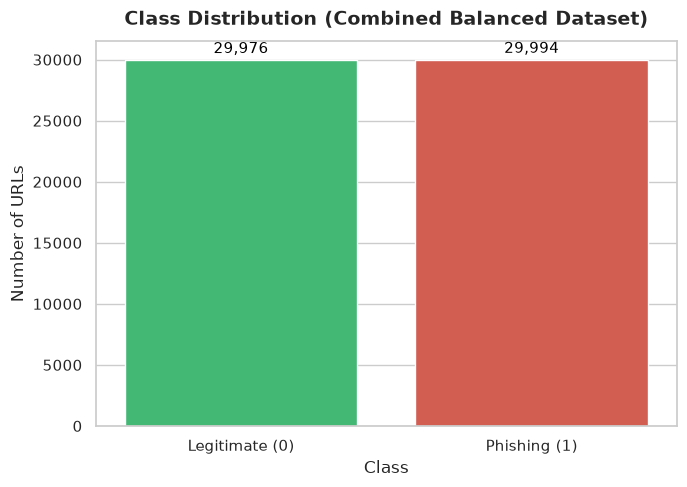

Saved reports/figures/class_distribution.png


In [6]:
# 1. Class Distribution Bar Chart
plt.figure(figsize=(7, 5))
palette = ["#2ecc71", "#e74c3c"]  # Green for Legit, Red for Phishing
ax = sns.countplot(x="label", data=df_balanced, palette=palette)
plt.title("Class Distribution (Combined Balanced Dataset)", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Class", fontsize=12)
plt.ylabel("Number of URLs", fontsize=12)
plt.xticks(ticks=[0, 1], labels=["Legitimate (0)", "Phishing (1)"])

for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha="center", va="baseline", fontsize=11, color="black", xytext=(0, 5),
                textcoords="offset points")

plt.tight_layout()
plt.savefig("../reports/figures/class_distribution.png", dpi=300)
plt.show()
print("Saved reports/figures/class_distribution.png")


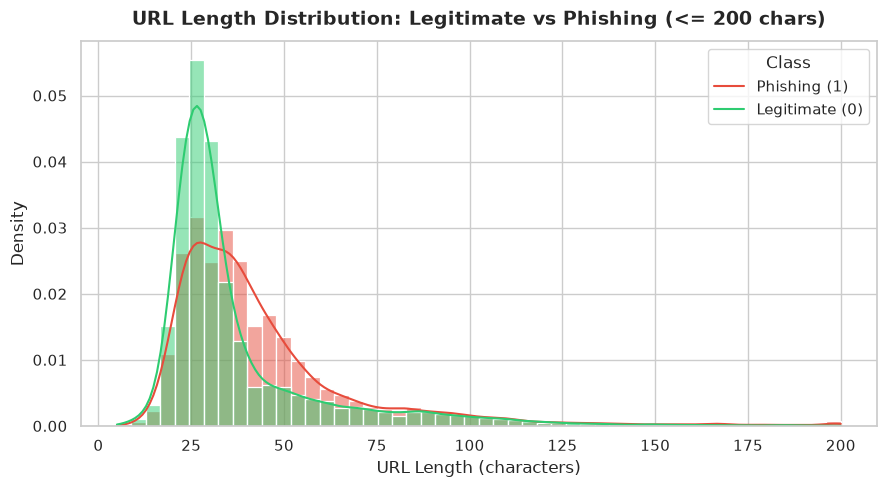

Saved reports/figures/url_length_distribution.png


In [7]:
# 2. URL Length Distribution (Histogram & KDE)
plt.figure(figsize=(9, 5))
length_vis = df_balanced[df_balanced["url_length"] <= 200]

sns.histplot(data=length_vis, x="url_length", hue="label", kde=True,
             palette=["#2ecc71", "#e74c3c"], bins=50, alpha=0.5, stat="density", common_norm=False)

plt.title("URL Length Distribution: Legitimate vs Phishing (<= 200 chars)", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("URL Length (characters)", fontsize=12)
plt.ylabel("Density", fontsize=12)
plt.legend(title="Class", labels=["Phishing (1)", "Legitimate (0)"])
plt.tight_layout()
plt.savefig("../reports/figures/url_length_distribution.png", dpi=300)
plt.show()
print("Saved reports/figures/url_length_distribution.png")


C:\Users\shrey\AppData\Local\Temp\ipykernel_9772\2021455786.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="label", y="url_length", data=df_balanced, palette=["#2ecc71", "#e74c3c"], showfliers=False)


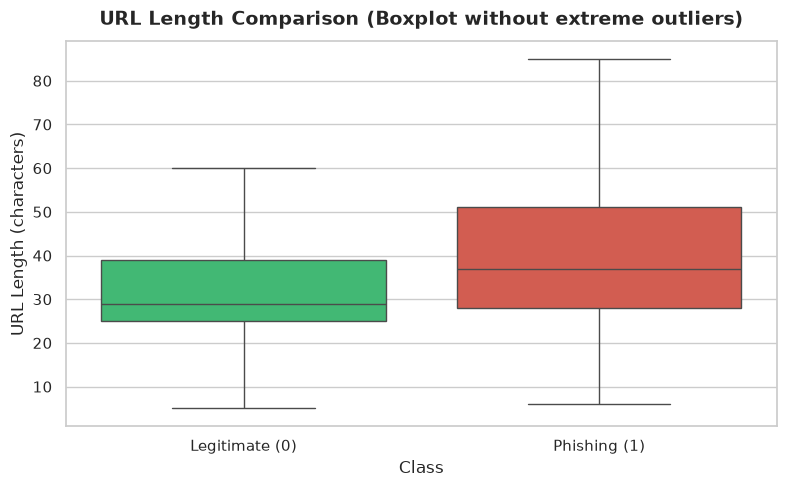

Saved reports/figures/url_length_boxplot.png


In [8]:
# 3. URL Length Boxplot
plt.figure(figsize=(8, 5))
sns.boxplot(x="label", y="url_length", data=df_balanced, palette=["#2ecc71", "#e74c3c"], showfliers=False)
plt.title("URL Length Comparison (Boxplot without extreme outliers)", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Class", fontsize=12)
plt.ylabel("URL Length (characters)", fontsize=12)
plt.xticks(ticks=[0, 1], labels=["Legitimate (0)", "Phishing (1)"])
plt.tight_layout()
plt.savefig("../reports/figures/url_length_boxplot.png", dpi=300)
plt.show()
print("Saved reports/figures/url_length_boxplot.png")


## 7. Export Cleaned Balanced Dataset

We export `data/processed/cleaned_urls.csv` containing the merged, balanced 60,000 URLs with `url`, `type`, and `label`.


In [9]:
output_csv = "../data/processed/cleaned_urls.csv"
df_balanced[["url", "type", "label"]].to_csv(output_csv, index=False)
print(f"Cleaned balanced dataset saved to: {output_csv}")
print(f"Final shape: {df_balanced[['url', 'type', 'label']].shape}")


Cleaned balanced dataset saved to: ../data/processed/cleaned_urls.csv
Final shape: (59970, 3)
